# Demand, inventory, and procurement

In [1]:
from pathlib import Path
import sys
import duckdb, pandas as pd, matplotlib.pyplot as plt
root=next(path for path in [Path.cwd(), *Path.cwd().parents] if (path/'config/default.json').exists())
sys.path.insert(0,str(root))
output=root/'artifacts'
figures=root/'reports/figures'
db=duckdb.connect(str(output/'operations.duckdb'),read_only=True,config={'threads':2})
def read(name):
    return pd.read_csv(output/f'{name}.csv')

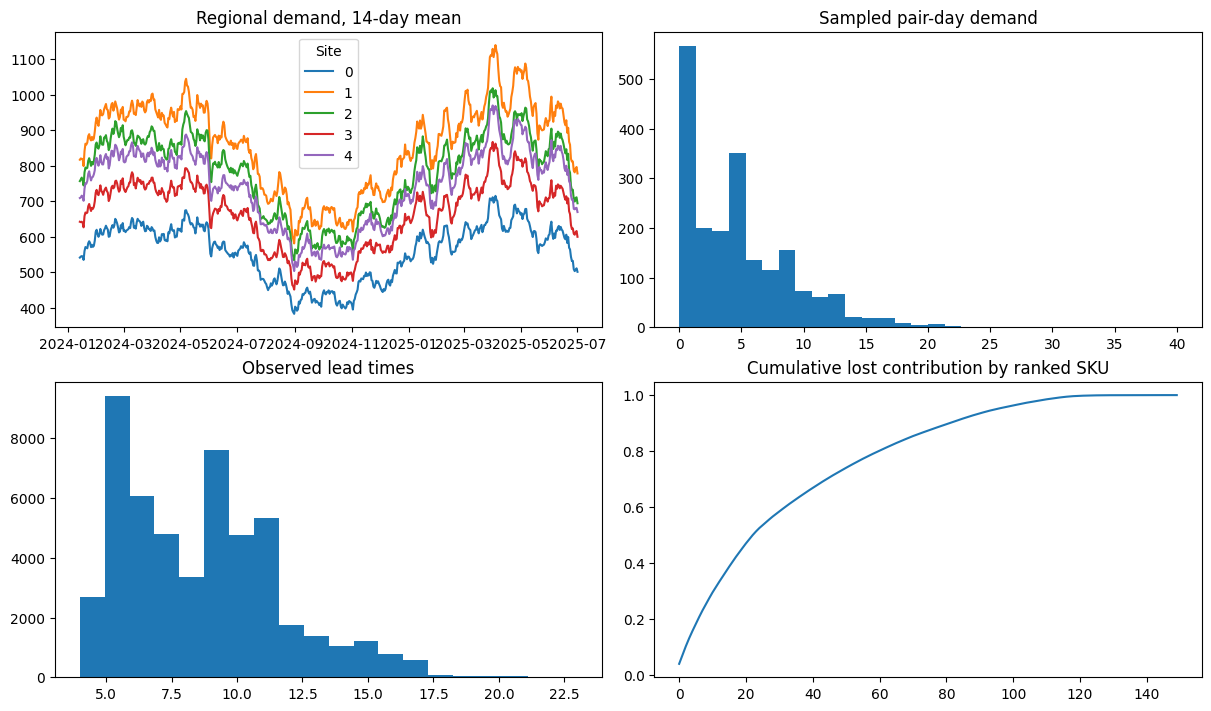

01_warehouse


,site,fill_rate,stockout_rate,lost_cost,average_inventory
0,1,0.804229,0.167445,854206.83,30887.765201
1,2,0.828695,0.146071,699639.53,32616.304124
2,4,0.852479,0.121192,596639.91,33907.961843
3,3,0.881037,0.098041,385984.74,37324.192865
4,0,0.927546,0.054951,199868.41,41284.677391


03_abc


,sku,throughput,share_before,abc
0,33,395951.95,0.000000,A
1,133,374654.91,0.025045,A
2,127,367343.34,0.048743,A
3,19,351748.16,0.071979,A
4,74,335346.20,0.094228,A


04_xyz


,sku,cv,xyz
0,34,1.132600,Z
1,56,1.112530,Z
2,72,1.103772,Z
3,142,1.077308,Z
4,62,1.028245,Z


... (7 outputs left out)

,site,stockout_days,coverable_days,coverable_cost
0,1,13764,13654.0,844209.72
1,2,12007,11892.0,689758.35
2,4,9962,9859.0,586767.48
3,3,8059,7972.0,379219.01
4,0,4517,4438.0,194262.80


,weekday,mean_units
0,Saturday,5.375402
1,Friday,5.168615
2,Thursday,4.701385
3,Monday,4.660000
4,Tuesday,4.636979
5,Wednesday,4.555624
6,Sunday,4.540274


,calendar_month,mean_units,stockout_share
0,1,4.878860,0.111570
1,2,5.195018,0.149076
2,3,5.606473,0.159484
3,4,5.408133,0.165022
4,5,5.314215,0.152860
5,6,4.867156,0.121044
6,7,4.308833,0.091042
7,8,3.798925,0.060774
8,9,3.762356,0.047600
9,10,3.603011,0.046323


,bucket,demand_sd,stockout_share
0,1,1.247413,0.065333
1,2,2.067311,0.106102
2,3,2.883984,0.127290
3,4,4.338751,0.171436


In [2]:
d = db.sql("SELECT date,site,sum(demand) demand,sum(lost_cost) lost_cost FROM daily GROUP BY 1,2 ORDER BY 1,2").df()
fig, axes = plt.subplots(2,2,figsize=(12,7), layout='constrained')
for site, g in d.groupby('site'):
    axes[0,0].plot(g.date,g.demand.rolling(14).mean(),label=str(site))
axes[0,0].set_title('Regional demand, 14-day mean')
axes[0,0].legend(title='Site')
raw = db.sql("SELECT demand,demand_sd FROM daily USING SAMPLE reservoir(2000 ROWS) REPEATABLE(42)").df()
axes[0,1].hist(raw.demand,bins=30)
axes[0,1].set_title('Sampled pair-day demand')
axes[1,0].hist(db.sql('SELECT lead_days FROM receipts').df().lead_days,bins=20)
axes[1,0].set_title('Observed lead times')
costs = read('02_sku_stockouts').lost_cost.sort_values(ascending=False)
axes[1,1].plot(costs.cumsum().to_numpy()/costs.sum())
axes[1,1].set_title('Cumulative lost contribution by ranked SKU')
fig.savefig(figures/'operations.png',dpi=130)
plt.show()
for key in ['01_warehouse','03_abc','04_xyz','05_supplier_otd','06_lead_variability','07_imbalance','13_donor_stock']:
    print(key)
    display(read(key).head())
display(db.sql("SELECT dayname(date) AS weekday, avg(demand) AS mean_units FROM daily GROUP BY 1 ORDER BY mean_units DESC").df())
display(db.sql("SELECT month(date) AS calendar_month, avg(demand) AS mean_units, avg((lost>0)::INT) AS stockout_share FROM daily GROUP BY 1 ORDER BY 1").df())
display(db.sql("SELECT bucket,avg(demand_sd) demand_sd, avg((lost>0)::INT) stockout_share FROM (SELECT *,ntile(4) OVER(ORDER BY demand_sd,site,sku,date) AS bucket FROM daily) GROUP BY 1 ORDER BY 1").df())

Coverage gaps and loss concentration motivate pair-level triage. Supplier receipts describe completed orders and exclude open orders.